# 用执行结果训练工具策略 / GRPO with mock tools

请求是“查询 AAPL 在 day2 的价格”，一个候选调用查了 AAPL，另一个却查了 MSFT。
两段 JSON 都能解析，参数是否正确还需要与请求核对，再执行模拟工具检查返回值。
我们把格式、参数和执行结果拆开打分，然后让同一请求下的候选调用相互比较。

CPU 默认 500 步语法预训练、180 轮 GRPO，每组 8 个候选。小型 GRU 生成三个调用词和 EOS，
由确定性渲染器转为 JSON。数据与金融数值由本地 mock 工具生成。


In [1]:
import importlib.util
import subprocess
import sys

packages = {"torch": "torch>=2.5,<3", "numpy": "numpy>=1.26,<3",
            "matplotlib": "matplotlib>=3.8,<4"}
missing = [spec for name, spec in packages.items() if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import copy
import json
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

torch.set_num_threads(1)
torch.manual_seed(12)
random.seed(12)
OUTPUT = Path(os.getenv("HANDS_ON_LAB_OUTPUT", "lab-output")) / "financial"
OUTPUT.mkdir(parents=True, exist_ok=True)
SFT_STEPS, UPDATES, GROUP, BETA = 500, 180, 8, 0.02
print({"syntax_updates": SFT_STEPS, "grpo_updates": UPDATES, "group_size": GROUP})


{'syntax_updates': 500, 'grpo_updates': 180, 'group_size': 8}


## 1. 固定数据、模拟工具和独立留出请求 / Data and verifier

训练和留出按“工具、实体、日期或金额”的组合划分，相同请求不会只改一句措辞后放入两侧。
所有调用词可以出现在语法预训练中；语法预训练的目标与请求参数随机配对，
只提供一个能尝试工具的初始策略。GRPO 的奖励只使用训练侧请求。


In [2]:
rows = []
for kind, entities, periods, function in [
    ("price", ["AAPL", "MSFT", "TSLA"], ["day1", "day2"], "get_stock_price"),
    ("revenue", ["Apple", "Microsoft", "Tesla"], ["2024", "2025"], "get_revenue"),
    ("convert", ["100", "200", "300"], ["USD_EUR", "EUR_USD"], "convert_currency"),
]:
    for i, entity in enumerate(entities):
        for j, period in enumerate(periods):
            rows.append({"prompt": [kind, entity, period], "call": [function, entity, period],
                         "test": (i + j) % 3 == 0})
rows += [{"prompt": ["poem", "none", "none"], "call": ["no_call", "none", "none"],
          "test": False}, {"prompt": ["story", "none", "none"],
                           "call": ["no_call", "none", "none"], "test": True}]
train_rows = [row for row in rows if not row["test"]]
heldout = [row for row in rows if row["test"]]
assert not ({tuple(row["prompt"]) for row in train_rows}
            & {tuple(row["prompt"]) for row in heldout})


def render_call(program):
    if len(program) != 4 or program[-1] != "<eos>":
        return "invalid program"
    name, first, second, _ = program
    if name == "get_stock_price":
        args = {"ticker": first, "date": second}
    elif name == "get_revenue":
        if second not in ["2024", "2025"]:
            return "invalid year"
        args = {"company": first, "fiscal_year": int(second)}
    elif name == "convert_currency":
        if first not in ["100", "200", "300"] or second not in ["USD_EUR", "EUR_USD"]:
            return "invalid conversion"
        source, destination = second.split("_")
        args = {"amount": int(first), "from_currency": source, "to_currency": destination}
    elif name == "no_call" and first == second == "none":
        args = {}
    else:
        return "unknown tool"
    return json.dumps({"name": name, "arguments": args}, sort_keys=True)


def execute_tool(call):
    name, args = call["name"], call["arguments"]
    if name == "get_stock_price":
        return {("AAPL", "day1"): 10, ("AAPL", "day2"): 11,
                ("MSFT", "day1"): 20, ("MSFT", "day2"): 21,
                ("TSLA", "day1"): 30, ("TSLA", "day2"): 31}[(args["ticker"], args["date"])]
    if name == "get_revenue":
        return {"Apple": 100, "Microsoft": 200, "Tesla": 300}[args["company"]] + (
            args["fiscal_year"] - 2024) * 7
    if name == "convert_currency":
        rate = {("USD", "EUR"): 0.9, ("EUR", "USD"): 1.1}[
            (args["from_currency"], args["to_currency"])]
        return round(args["amount"] * rate, 2)
    if name == "no_call" and args == {}:
        return "no_call"
    raise ValueError("Unknown mock call")


def score(program, row):
    text = render_call(program)
    gold = json.loads(render_call(row["call"] + ["<eos>"]))
    try:
        call = json.loads(text)
        same_schema = (call["name"] == gold["name"]
                       and call["arguments"].keys() == gold["arguments"].keys())
        exact = call == gold
        try:
            executed = exact and execute_tool(call) == execute_tool(gold)
        except (KeyError, ValueError, TypeError):
            executed = False
        return [1.0, float(same_schema), float(exact), float(executed)]
    except (ValueError, TypeError, KeyError):
        return [0.0] * 4


for row in rows:
    assert score(row["call"] + ["<eos>"], row) == [1.0] * 4
assert score(["unknown", "none", "none", "<eos>"], rows[0]) == [0.0] * 4
assert score(["get_stock_price", "MSFT", "day1", "<eos>"], rows[0])[2:] == [0, 0]
print({"training_requests": len(train_rows), "heldout_requests": len(heldout),
       "sample_prompt": rows[0]["prompt"], "gold_call": render_call(rows[0]["call"] + ["<eos>"])})


{'training_requests': 13, 'heldout_requests': 7, 'sample_prompt': ['price', 'AAPL', 'day1'], 'gold_call': '{"arguments": {"date": "day1", "ticker": "AAPL"}, "name": "get_stock_price"}'}


## 2. 先学调用语法 / A small autoregressive policy

词表包括工具名和可用参数，GRU 逐词生成调用，概率形状保留 `[batch, token]`。
渲染器只决定表示方式，不读取标准答案；参数填错时仍会生成错误的 JSON，并接受低奖励。


In [3]:
words = ["<pad>", "<sep>", "<eos>"] + sorted({word for row in rows
                                                    for word in row["prompt"] + row["call"]})
vocab = {word: index for index, word in enumerate(words)}


class ToolLM(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(words), 32)
        self.gru = nn.GRU(32, 64, batch_first=True)
        self.head = nn.Linear(64, len(words))

    def forward(self, tokens):
        hidden, _ = self.gru(self.embedding(tokens))
        return self.head(hidden)


def encode_prompts(batch):
    return torch.tensor([[vocab[w] for w in row["prompt"] + ["<sep>"]] for row in batch])


def token_logp(policy, prompts, responses):
    tokens = torch.cat([prompts, responses], -1)
    # 提示词长为 4，位置 3 的预测对应回答的第一个词。
    logits = policy(tokens[:, :-1])[:, prompts.shape[1] - 1:]
    return logits.log_softmax(-1).gather(-1, responses[..., None]).squeeze(-1)


@torch.no_grad()
def sample(policy, prompts, greedy=False):
    tokens, responses = prompts.clone(), []
    for _ in range(4):
        logits = policy(tokens)[:, -1]
        next_token = logits.argmax(-1) if greedy else torch.distributions.Categorical(
            logits=logits).sample()
        responses.append(next_token)
        tokens = torch.cat([tokens, next_token[:, None]], -1)
    return torch.stack(responses, -1)


def decode(response):
    return [words[i] for i in response.tolist()]


model = ToolLM()
optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
for _ in range(SFT_STEPS):
    batch = random.choices(train_rows, k=24)
    random_calls = [random.choice([r for r in rows if r["call"][0] == row["call"][0]])["call"]
                    for row in batch]
    responses = torch.tensor([[vocab[w] for w in call + ["<eos>"]] for call in random_calls])
    loss = -token_logp(model, encode_prompts(batch), responses).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
reference = copy.deepcopy(model).eval().requires_grad_(False)


@torch.no_grad()
def evaluate(policy, dataset=None):
    dataset = heldout if dataset is None else dataset
    response = sample(policy, encode_prompts(dataset), greedy=True)
    details = [score(decode(item), row) for item, row in zip(response, dataset)]
    names = ["rendered_json_rate", "schema_rate", "argument_accuracy", "execution_success"]
    metrics = dict(zip(names, np.array(details).mean(0).tolist()))
    return metrics, [render_call(decode(item)) for item in response]


before, before_text = evaluate(model)
before_train = evaluate(model, train_rows)[0]
print("Before GRPO:", before)


Before GRPO: {'rendered_json_rate': 1.0, 'schema_rate': 1.0, 'argument_accuracy': 0.14285714285714285, 'execution_success': 0.14285714285714285}


## 3. 每个请求独立采样一组，再逐词更新 / Group-relative optimization

奖励为格式 0.2、schema 0.2、参数 0.3、执行结果 0.3 的加权和。
每组奖励独立标准化，组内全相同时优势为 0。先保存旧策略采样时的逐词概率，
再做两轮裁剪更新；参考策略固定，KL 项也按 token 计算，最后按回答长度平均。
固定四词回答使 mask 全为 1；通用变长实现需要排除 EOS 之后的 padding。


In [4]:
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)
training_rewards, heldout_curve = [], []
for update in range(UPDATES):
    batch = random.choices(train_rows, k=8)
    expanded = [row for row in batch for _ in range(GROUP)]
    prompts = encode_prompts(expanded)
    responses = sample(model, prompts)
    scores = torch.tensor([score(decode(item), row) for item, row in zip(responses, expanded)])
    rewards = (scores * torch.tensor([0.2, 0.2, 0.3, 0.3])).sum(-1).reshape(-1, GROUP)
    advantage = (rewards - rewards.mean(-1, keepdim=True)) / (
        rewards.std(-1, correction=0, keepdim=True) + 1e-4)
    advantage = advantage.flatten().detach()
    with torch.no_grad():
        old_logp = token_logp(model, prompts, responses)
        ref_logp = token_logp(reference, prompts, responses)
    for _ in range(2):
        logp = token_logp(model, prompts, responses)
        ratio = torch.exp(logp - old_logp)
        clipped = ratio.clamp(0.8, 1.2)
        surrogate = torch.minimum(ratio * advantage[:, None], clipped * advantage[:, None])
        log_ref_ratio = ref_logp - logp
        kl = torch.exp(log_ref_ratio) - log_ref_ratio - 1
        loss = (-surrogate + BETA * kl).mean(-1).mean()
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1)
        optimizer.step()
    training_rewards.append(float(rewards.mean()))
    if update % 15 == 0:
        heldout_curve.append((update, evaluate(model)[0]["execution_success"]))
after, after_text = evaluate(model)
after_train = evaluate(model, train_rows)[0]
assert any(not torch.equal(value, reference.state_dict()[key])
           for key, value in model.state_dict().items())
assert np.isfinite(training_rewards).all()
print("Held-out before:", before, "\nHeld-out after:", after)
print("Training requests before:", before_train, "\nTraining requests after:", after_train)
for row, old, new in zip(heldout[:4], before_text, after_text):
    print(row["prompt"], "\n before:", old, "\n after:", new)


Held-out before: {'rendered_json_rate': 1.0, 'schema_rate': 1.0, 'argument_accuracy': 0.14285714285714285, 'execution_success': 0.14285714285714285} 
Held-out after: {'rendered_json_rate': 1.0, 'schema_rate': 1.0, 'argument_accuracy': 0.14285714285714285, 'execution_success': 0.14285714285714285}
Training requests before: {'rendered_json_rate': 1.0, 'schema_rate': 1.0, 'argument_accuracy': 0.3076923076923077, 'execution_success': 0.3076923076923077} 
Training requests after: {'rendered_json_rate': 1.0, 'schema_rate': 1.0, 'argument_accuracy': 0.5384615384615384, 'execution_success': 0.5384615384615384}
['price', 'AAPL', 'day1'] 
 before: {"arguments": {"date": "day2", "ticker": "AAPL"}, "name": "get_stock_price"} 
 after: {"arguments": {"date": "day2", "ticker": "AAPL"}, "name": "get_stock_price"}
['price', 'TSLA', 'day2'] 
 before: {"arguments": {"date": "day2", "ticker": "AAPL"}, "name": "get_stock_price"} 
 after: {"arguments": {"date": "day2", "ticker": "AAPL"}, "name": "get_stock_

## 4. 格式通过和工具成功分别报告 / Inspect failures

训练奖励上升可能只来自格式正确。留出请求的完整执行成功率才同时要求工具、参数与结果正确。
下表逐条对照请求、生成参数与执行结果。
如果训练请求成功率提高、留出请求却没有提高，就得到了一次参数组合泛化失败。
可以检验两种解释：训练请求覆盖不足，或小模型未学会复制请求中的参数。
增加训练侧组合和加入参数复制的监督预训练，分别构成两个独立的后续对照。


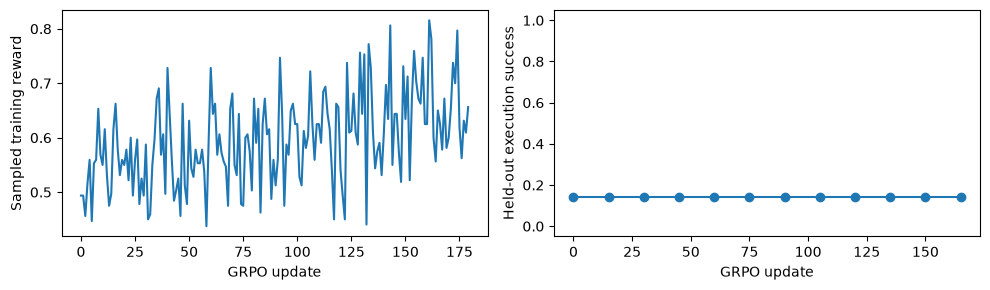

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(training_rewards)
axes[0].set(xlabel="GRPO update", ylabel="Sampled training reward")
curve = np.array(heldout_curve)
axes[1].plot(curve[:, 0], curve[:, 1], marker="o")
axes[1].set(xlabel="GRPO update", ylabel="Held-out execution success", ylim=(-0.05, 1.05))
fig.tight_layout()
fig.savefig(OUTPUT / "training.png", dpi=120)
plt.show()
metrics = {"before": before, "after": after,
           "training_before": before_train, "training_after": after_train,
           "examples": [{"prompt": row["prompt"], "before": old, "after": new}
                        for row, old, new in zip(heldout, before_text, after_text)]}
(OUTPUT / "metrics.json").write_text(json.dumps(metrics, indent=2))
(OUTPUT / "dataset.json").write_text(json.dumps(rows, indent=2))
torch.save({"state_dict": model.state_dict(), "vocabulary": words}, OUTPUT / "tiny-tool-grpo.pt")


## 完成检查 / Checklist
- [ ] 验证器分别统计格式、schema、参数和执行结果，错误参数不能拿到执行奖励。
- [ ] GRPO 实际更新了策略参数，使用旧策略的逐词概率和固定参考策略。
- [ ] 留出请求按语义组合隔离，并保留失败调用。

## 练习 / Exercise
调用能解析、schema 正确，但参数和结果错误时，填入它的总奖励。
提示：只加前两个权重。


In [6]:
RUN_EXERCISE = False
answer = None
if RUN_EXERCISE:
    assert abs(answer - 0.4) < 1e-6
else:
    print("Optional exercise: fill answer and enable RUN_EXERCISE.")


Optional exercise: fill answer and enable RUN_EXERCISE.


## 参考资料 / References
- [DeepSeekMath](https://arxiv.org/html/2402.03300)：
  对照组内优势、逐 token ratio、裁剪与 KL 的归约顺序。
- [本书金融工具调用](https://walkinglabs.github.io/hands-on-modern-rl/chapter18_grpo/financial-tool-calling-grpo)：
  将相同验证过程接入 Qwen 语言模型。


## 本次运行结果

CPU · Python 3.12.13 · 2.91 s

[查看完整结果页](https://walkinglabs.github.io/hands-on-modern-rl/lab-results/financial-zh.html)
